# Producto Analítico Final — Siniestralidad Vial Colombia
**Minería de Datos · Checkpoint 3 · Noviembre 2026**

**Integrantes:**
- Andrés Felipe Patiño
- Bryan Bedoya Calderón
- Juan Camilo Arenas Villa

**Repositorio:** https://github.com/JuanCamilo620/siniestralidad-vial-colombia

---

## Objetivo

Este notebook combina los hallazgos de las 8 unidades del curso en **6 visualizaciones** que responden a la pregunta de negocio:

> ¿Qué sectores viales, horarios y condiciones concentran la mayor siniestralidad vial en Colombia, para priorizar intervenciones de infraestructura y controles de tránsito?

**No repite el código de las unidades anteriores.** Solo muestra lo que significan esos resultados juntos.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Subir el archivo desde tu Mac
print("Sube el archivo dataset_con_anomalias.csv:")
subidos = files.upload()

# Cargar el dataset (Colab lo guarda en la raíz, sin la carpeta data/)
df = pd.read_csv("dataset_con_anomalias.csv")

print(f"Dataset cargado: {df.shape}")
print(f"Columnas: {len(df.columns)}")
print(f"\nPrimeras columnas:")
print(df.columns.tolist()[:20])

Sube el archivo dataset_con_anomalias.csv:


Saving dataset_con_anomalias.csv to dataset_con_anomalias (1).csv
Dataset cargado: (316, 42)
Columnas: 42

Primeras columnas:
['ID_MT', 'GiZScore', 'Fallecidos', 'GiPValue', 'Tramo', 'Nombre', 'Latitud', 'Longitud', 'PR', 'Municipio', 'Departamento', 'divipola', 'Departamento_norm', 'Municipio_norm', 'total_fallecidos', 'PR_valido', 'Tramo_valido', 'ratio_reciente_historico', 'es_corredor_nacional', 'ENTIDAD_ANI']


## Gráfico 1 — ¿Dónde se concentran los tramos críticos?

Combinamos los hallazgos del EDA (Unidad 3) y la segmentación (Unidad 5) para mostrar los departamentos con más tramos de alto riesgo.

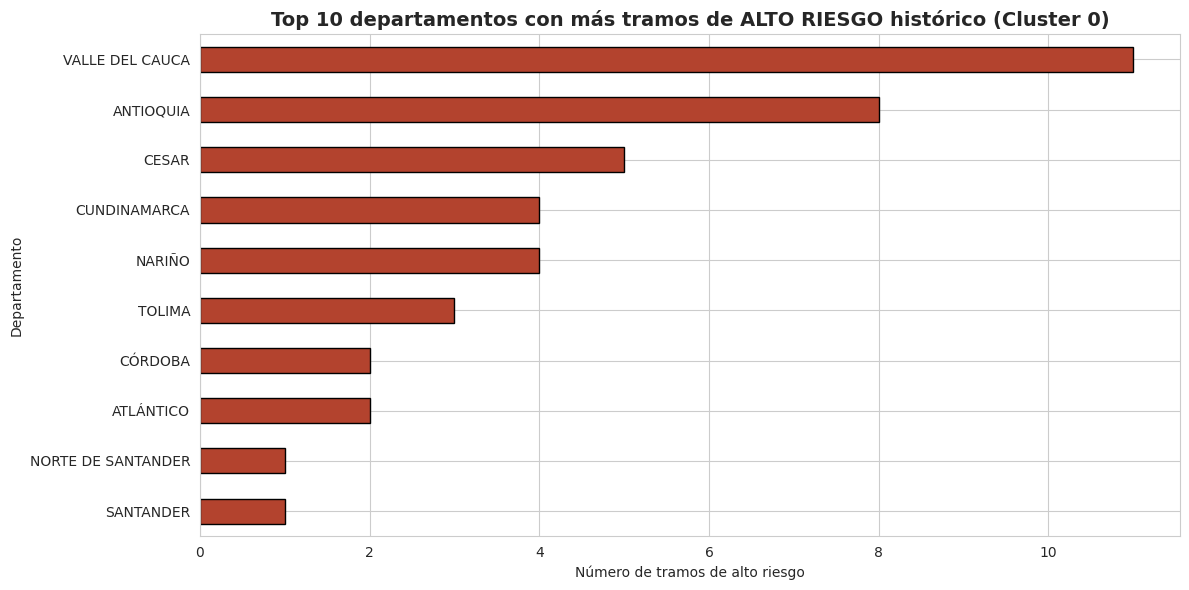


Total tramos de alto riesgo: 46
Departamentos afectados: 15


In [6]:
# Gráfico 1: Top 10 departamentos por tramos de alto riesgo
alto_riesgo = df[df["cluster"] == 0]  # Cluster 0 = alto riesgo histórico

top_deptos = alto_riesgo["Departamento"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(12, 6))
top_deptos.plot(kind="barh", ax=ax, color="#b3432e", edgecolor="black")
ax.set_title("Top 10 departamentos con más tramos de ALTO RIESGO histórico (Cluster 0)", fontsize=14, fontweight="bold")
ax.set_xlabel("Número de tramos de alto riesgo")
ax.set_ylabel("Departamento")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print(f"\nTotal tramos de alto riesgo: {len(alto_riesgo)}")
print(f"Departamentos afectados: {alto_riesgo['Departamento'].nunique()}")

## Gráfico 2 — ¿Qué entidades administran los tramos más letales?

Combinamos el EDA (Unidad 3) con la segmentación (Unidad 5) para mostrar qué entidades concentran los tramos de alto riesgo.

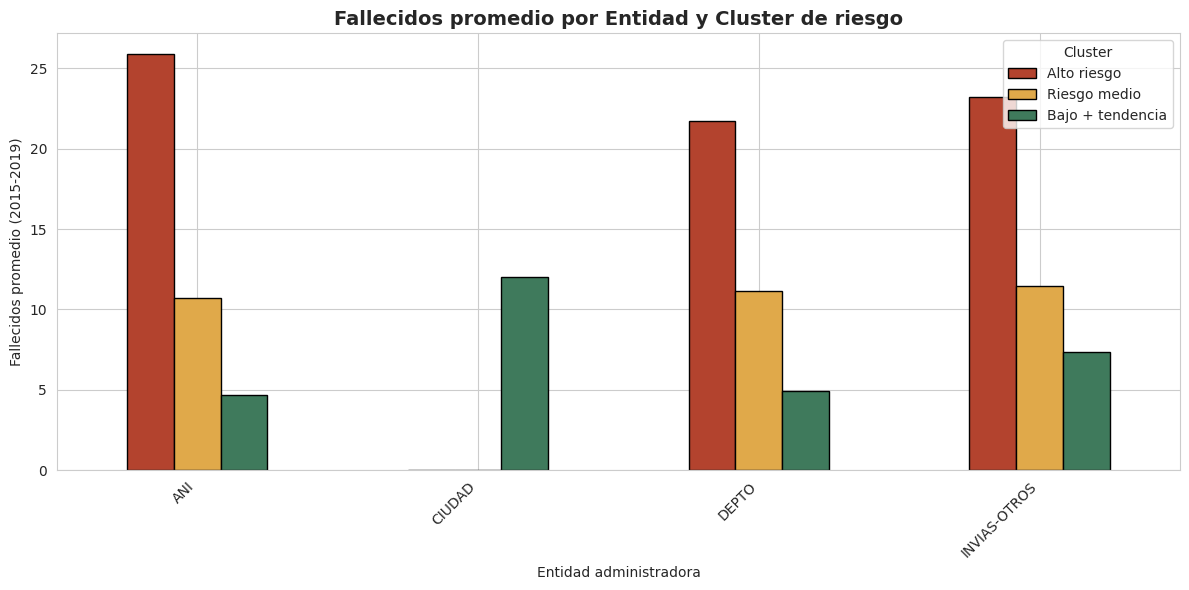

In [7]:
# Gráfico 2: Fallecidos promedio por ENTIDAD y cluster
fig, ax = plt.subplots(figsize=(12, 6))

# Reconstruir ENTIDAD a partir de las columnas one-hot
df["ENTIDAD_original"] = df[
    ["ENTIDAD_ANI", "ENTIDAD_CIUDAD", "ENTIDAD_DEPTO", "ENTIDAD_INVIAS-OTROS"]
].idxmax(axis=1).str.replace("ENTIDAD_", "")

pivot = df.groupby(["ENTIDAD_original", "cluster"])["Fallecidos"].mean().unstack()
pivot.plot(kind="bar", ax=ax, color=["#b3432e", "#e0a94a", "#3f7a5c"], edgecolor="black")
ax.set_title("Fallecidos promedio por Entidad y Cluster de riesgo", fontsize=14, fontweight="bold")
ax.set_xlabel("Entidad administradora")
ax.set_ylabel("Fallecidos promedio (2015-2019)")
ax.legend(title="Cluster", labels=["Alto riesgo", "Riesgo medio", "Bajo + tendencia"])
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Gráfico 3 — ¿Qué tramos son los más letales?

Del EDA (Unidad 3) y la detección de anomalías (Unidad 7): los 10 tramos con más fallecidos históricos.

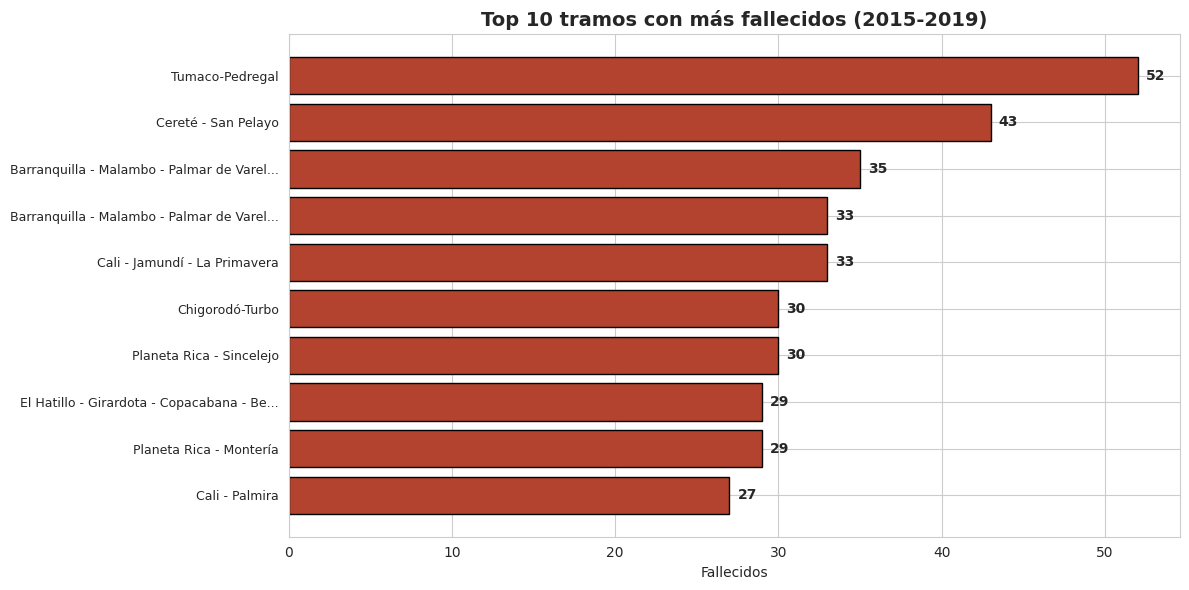

In [8]:
# Gráfico 3: Top 10 tramos con más fallecidos
top_tramos = df.nlargest(10, "Fallecidos")[["Tramo", "Fallecidos", "Departamento"]]

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(range(len(top_tramos)), top_tramos["Fallecidos"], color="#b3432e", edgecolor="black")
ax.set_yticks(range(len(top_tramos)))
ax.set_yticklabels([f"{row['Tramo'][:40]}..." if len(str(row['Tramo'])) > 40 else row['Tramo'] for _, row in top_tramos.iterrows()], fontsize=9)
ax.set_title("Top 10 tramos con más fallecidos (2015-2019)", fontsize=14, fontweight="bold")
ax.set_xlabel("Fallecidos")
ax.invert_yaxis()

for i, v in enumerate(top_tramos["Fallecidos"]):
    ax.text(v + 0.5, i, str(v), va="center", fontweight="bold")

plt.tight_layout()
plt.show()

## Gráfico 4 — ¿Los tramos de alto riesgo histórico siguen siendo prioritarios hoy?

Combinamos la segmentación (Unidad 5) con la ingeniería de características (Unidad 4): scatter de fallecidos históricos vs ratio reciente/histórico, coloreado por cluster.

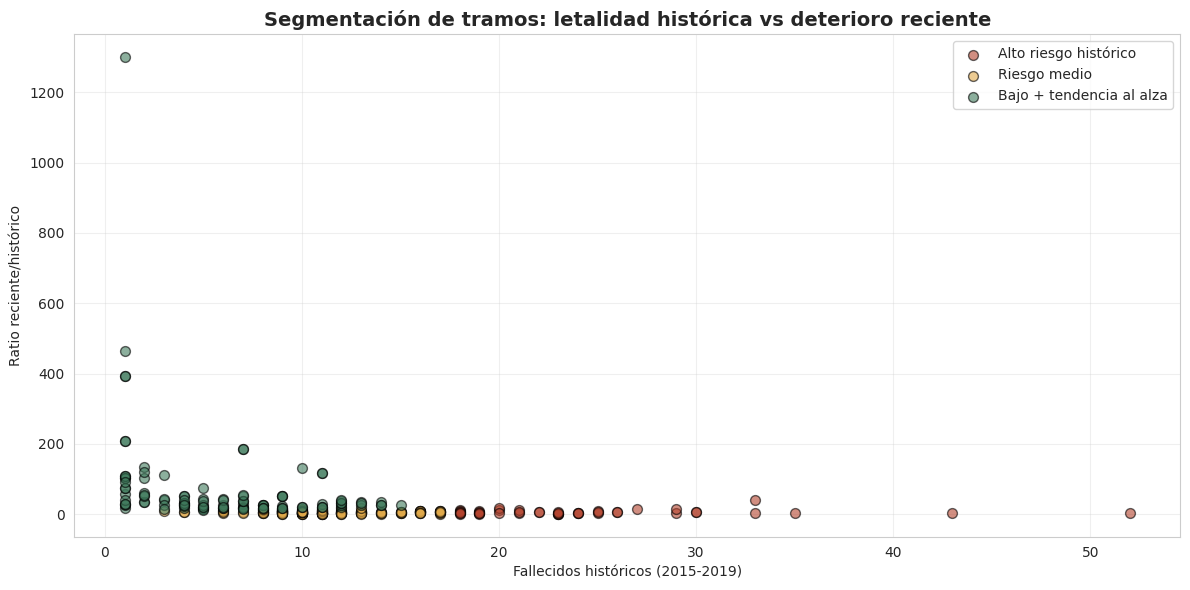

In [9]:
# Gráfico 4: Scatter Fallecidos vs ratio reciente, coloreado por cluster
fig, ax = plt.subplots(figsize=(12, 6))

colores = {0: "#b3432e", 1: "#e0a94a", 2: "#3f7a5c"}
nombres = {0: "Alto riesgo histórico", 1: "Riesgo medio", 2: "Bajo + tendencia al alza"}

for cluster in [0, 1, 2]:
    subset = df[df["cluster"] == cluster]
    ax.scatter(subset["Fallecidos"], subset["ratio_reciente_historico"],
               label=nombres[cluster], color=colores[cluster], alpha=0.6, s=50, edgecolors="black")

ax.set_xlabel("Fallecidos históricos (2015-2019)")
ax.set_ylabel("Ratio reciente/histórico")
ax.set_title("Segmentación de tramos: letalidad histórica vs deterioro reciente", fontsize=14, fontweight="bold")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Gráfico 5 — ¿Qué tramos son anómalos?

De la técnica complementaria (Unidad 7): los tramos marcados como anómalos por Isolation Forest.

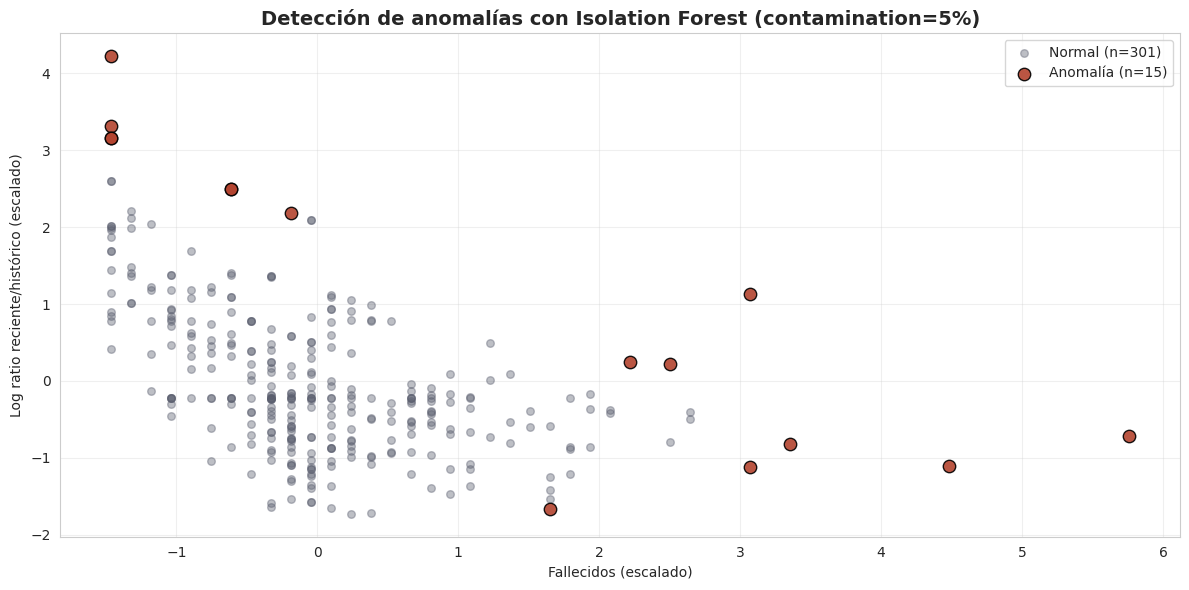


Anomalías detectadas: 15 de 316 (4.7%)


In [10]:
# Gráfico 5: Anomalías detectadas
fig, ax = plt.subplots(figsize=(12, 6))

normales = df[~df["es_anomalia"]]
anomalos = df[df["es_anomalia"]]

ax.scatter(normales["Fallecidos_escalado"], normales["log_ratio_reciente_escalado"],
           alpha=0.4, label=f"Normal (n={len(normales)})", color="#5b5f6f", s=30)
ax.scatter(anomalos["Fallecidos_escalado"], anomalos["log_ratio_reciente_escalado"],
           alpha=0.9, label=f"Anomalía (n={len(anomalos)})", color="#b3432e", s=80, edgecolors="black")

ax.set_xlabel("Fallecidos (escalado)")
ax.set_ylabel("Log ratio reciente/histórico (escalado)")
ax.set_title("Detección de anomalías con Isolation Forest (contamination=5%)", fontsize=14, fontweight="bold")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nAnomalías detectadas: {len(anomalos)} de {len(df)} ({len(anomalos)/len(df)*100:.1f}%)")

## Gráfico 6 — ¿Qué nos dice el modelo predictivo?

De la Unidad 6: comparación del modelo con y sin fuga de datos.

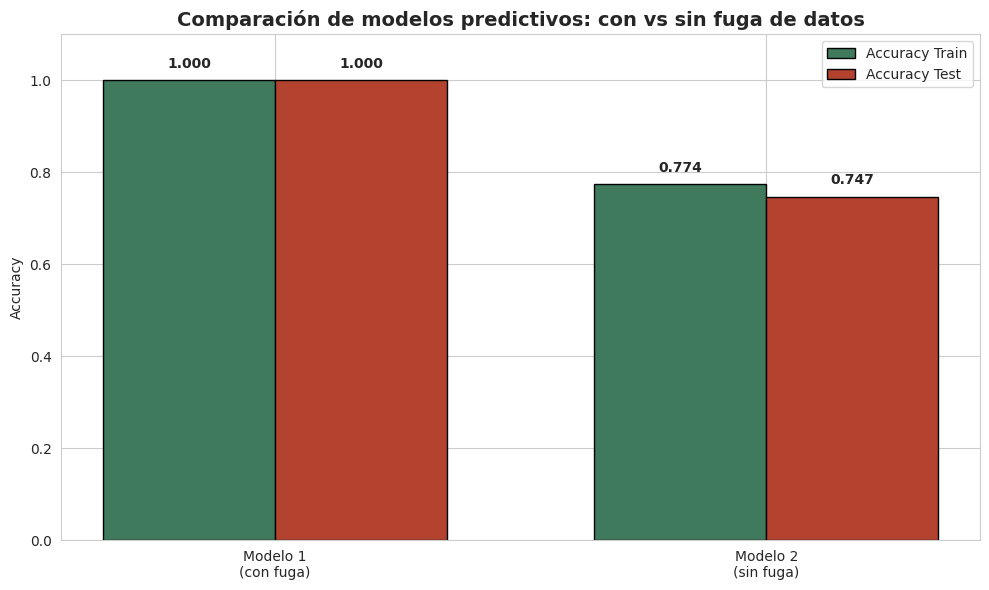


Modelo 1 (con fuga): accuracy perfecto por incluir 'Fallecidos' (fuga de datos).
Modelo 2 (sin fuga): accuracy honesto usando solo variables exógenas.


In [11]:
# Gráfico 6: Comparación de modelos
fig, ax = plt.subplots(figsize=(10, 6))

modelos = ["Modelo 1\n(con fuga)", "Modelo 2\n(sin fuga)"]
acc_train = [1.000, 0.774]
acc_test = [1.000, 0.747]

x = np.arange(len(modelos))
width = 0.35

bars1 = ax.bar(x - width/2, acc_train, width, label="Accuracy Train", color="#3f7a5c", edgecolor="black")
bars2 = ax.bar(x + width/2, acc_test, width, label="Accuracy Test", color="#b3432e", edgecolor="black")

ax.set_ylabel("Accuracy")
ax.set_title("Comparación de modelos predictivos: con vs sin fuga de datos", fontsize=14, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(modelos)
ax.legend()
ax.set_ylim(0, 1.1)

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{height:.3f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

print("\nModelo 1 (con fuga): accuracy perfecto por incluir 'Fallecidos' (fuga de datos).")
print("Modelo 2 (sin fuga): accuracy honesto usando solo variables exógenas.")

## Síntesis de hallazgos

Combinando los 6 gráficos, los hallazgos principales del proyecto son:

1. **Concentración geográfica:** los tramos de alto riesgo se concentran en pocos departamentos (Valle del Cauca, Antioquia, Cundinamarca, Santander). Esto permite priorizar intervenciones por región.

2. **Entidades administradoras:** los tramos de alto riesgo están a cargo principalmente de INVIAS-OTROS y ANI. Los operativos deben coordinarse con estas entidades.

3. **Tramos más letales:** Tumaco–Pedregal (Nariño, 52 fallecidos), Cereté–San Pelayo (Córdoba, 43) y Barranquilla–Malambo–Palmar de Varela (Atlántico, 35) son los corredores más críticos del país.

4. **Deterioro reciente:** el Cluster 2 (bajo riesgo histórico + tendencia al alza) incluye 100 tramos cuyo municipio empeoró mucho en 2021-2024. Requieren vigilancia.

5. **Anomalías detectadas:** 15 tramos tienen combinaciones extremas de letalidad y deterioro reciente. No son errores — son casos que requieren revisión manual prioritaria.

6. **Fuga de datos en el modelo:** el modelo con `Fallecidos` da accuracy perfecto (1.000) porque esa variable construye la respuesta. El modelo sin fuga da accuracy 0.747, que es la métrica honesta.

**Conclusión:** los tramos de alto riesgo histórico (Cluster 0) son la prioridad de infraestructura; los del Cluster 2 son la prioridad de vigilancia por deterioro reciente. Las anomalías detectadas deben revisarse manualmente antes de cualquier decisión.

In [12]:
# Guardar el notebook ejecutado
print("Producto analítico final listo.")
print(f"Gráficos construidos: 6")
print(f"Hallazgos sintetizados: 6")
print(f"Dataset usado: dataset_con_anomalias.csv ({df.shape[0]} filas × {df.shape[1]} columnas)")

Producto analítico final listo.
Gráficos construidos: 6
Hallazgos sintetizados: 6
Dataset usado: dataset_con_anomalias.csv (316 filas × 42 columnas)
